In [ ]:
import pandas as pd


In [3]:
# reading the csv file
df_population_raw = pd.read_csv('../population_total.csv')


In [4]:
# first look at the dataset
df_population_raw.head()


,country,year,population
0,China,2020.0,1.439324e+09
1,China,2019.0,1.433784e+09
2,China,2018.0,1.427648e+09
3,China,2017.0,1.421022e+09
4,China,2016.0,1.414049e+09


Task: In this exercise, we're going to reshape the population_total dataset, so we get the countries in the column names and the years in the index. This will helps us later when making visualizations.

In [5]:
# drop null values
df_population_raw.dropna(inplace=True)


In [6]:
# make a pivot table with .pivot() method (countries in the column names and the years in the index)
df_pivot = df_population_raw.pivot(index='year', columns='country', values='population')


In [7]:
# select only the countries 'United States', 'India', 'China', 'Indonesia', 'Brazil' and update the dataframe
df_pivot = df_pivot[['United States', 'India', 'China', 'Indonesia', 'Brazil']]


In [8]:
# show pivot table
df_pivot


country,United States,India,China,Indonesia,Brazil
year,,,,,
1955.0,171685336.0,4.098806e+08,6.122416e+08,77273425.0,62533919.0
1960.0,186720571.0,4.505477e+08,6.604081e+08,87751068.0,72179226.0
1965.0,199733676.0,4.991233e+08,7.242190e+08,100267062.0,83373530.0
1970.0,209513341.0,5.551898e+08,8.276014e+08,114793178.0,95113265.0
1975.0,219081251.0,6.231029e+08,9.262409e+08,130680727.0,107216205.0
1980.0,229476354.0,6.989528e+08,1.000089e+09,147447836.0,120694009.0
1985.0,240499825.0,7.843600e+08,1.075589e+09,164982451.0,135274080.0
1990.0,252120309.0,8.732778e+08,1.176884e+09,181413402.0,149003223.0
1995.0,265163745.0,9.639226e+08,1.240921e+09,196934260.0,162019896.0


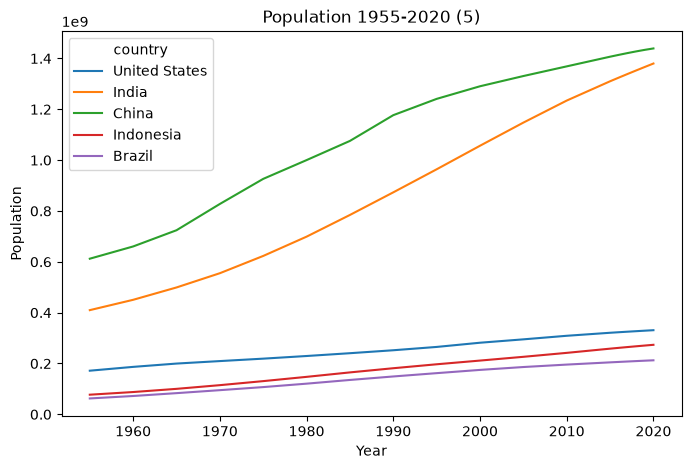

In [9]:
fx = df_pivot.plot(kind='line', xlabel='Year', ylabel='Population', figsize=(8,5), title='Population 1955-2020 (5)')


In [11]:
import plotly.express as px


In [15]:
fig = px.line(df_pivot, title="Population 1995-2020", template='ggplot2', labels={'value':'Population'})
fig.show()


In [16]:
# selecting only one year (2020)
df_pivot_2020 = df_pivot[df_pivot.index.isin([2020])]


In [ ]:
df_pivot_2020


country,United States,India,China,Indonesia,Brazil
year,,,,,
2020.0,331002651.0,1.380004e+09,1.439324e+09,273523615.0,212559417.0


In [18]:
# transpose dataframe from rows to columns or viceversa
df_pivot_2020 = df_pivot_2020.T


<Axes: title={'center': 'Population in 2020'}, xlabel='Years', ylabel='Population'>

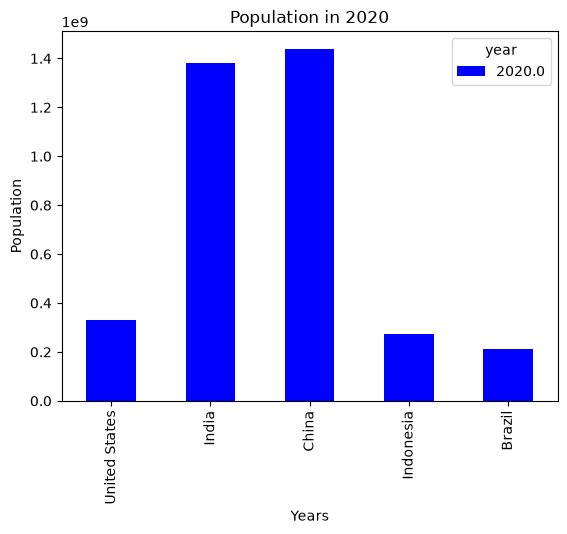

In [21]:
df_pivot_2020.plot(kind='bar', color='blue', xlabel='Years', ylabel='Population',
                    title='Population in 2020')


In [27]:
fig = px.bar(df_pivot_2020, title='Population in 2020', template='ggplot2', labels={'value':'Population'})
fig.show()


<Axes: title={'center': 'Population in 2020 (%)'}>

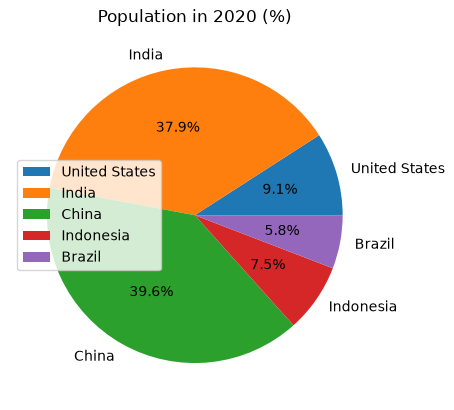

In [32]:
df_pivot_2020.rename(columns={2020: '2020'}, inplace=True)

df_pivot_2020.plot.pie(
    y='2020', 
    title='Population in 2020 (%)',
    autopct='%.1f%%',
    legend=True
)


In [31]:
import plotly.express as px

fig = px.pie(
    df_pivot_2020, 
    values='2020', 
    names=df_pivot_2020.index, 
    title='Population in 2020',
    template='seaborn'
)
fig.show()
